# Forecasting Hourly Bike Rental Demand

**Methodology:** CRISP-DM  
**Dataset:** UCI Bike Sharing (hourly), also used in Kaggle's Bike Sharing Demand competition; 17,379 hourly observations with weather and calendar fields. The target is cnt. casual and registered are excluded because they sum to cnt and would leak the answer.

This Colab-compatible notebook contains the executed analysis and saved outputs. Re-run top to bottom in Colab to reproduce; reports reflect the saved local run.

## Project charter

A city bike-share operator wants an hourly aggregate-demand estimate to support next-day staffing and capacity planning. This dataset has no station-level inventory or trip flows, so it cannot support bicycle redistribution decisions.

**Analytical objective:** Forecast hourly system-wide rentals from calendar features known in advance. Forecast origin: before the first hour of the service day; horizon: the next calendar day. Target-hour observed weather is excluded. Primary metric: MAE in bikes/hour; also report RMSE and RMSLE.

**Analytical screening gate:** on a final chronological quarter, calendar-only MAE must be at least 10% lower than a training-period median-by-weekday-and-hour baseline and must not be more than 10% worse within any represented season. This is a data-mining screening criterion only. Business success remains unresolved because planner error costs, decision utility, and incumbent workflow impact have not been measured; that gap independently blocks deployment. Stakeholders include operations, staffing planners, data owners, riders, and affected communities.

**Decision boundary:** the historical experiment does not establish business utility or justify operational deployment; it does not establish causal effects or future performance.

**Dataset provenance:** [Kaggle competition listing](https://www.kaggle.com/competitions/bike-sharing-demand); [UCI dataset record and citation](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset); reproducible download: [UCI archive](https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip). UCI lists the data as CC BY 4.0; retain attribution.

## Environment and reproducibility

The notebook installs common packages in Colab. The data are fetched from the public UCI archive. Fixed random seeds are used where sampling or initialization applies. A network connection is required for first execution.

In [1]:
# Colab-ready setup; rerun this cell if the runtime is reset.
%pip -q install pandas==3.1.0 numpy==2.5.4 scikit-learn==1.9.1 matplotlib==3.11.2 joblib==1.6.0
import hashlib, sklearn
from datetime import datetime, timezone
from IPython.display import display
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_squared_log_error
print("Environment ready", {"pandas":pd.__version__,"numpy":np.__version__,"scikit_learn":sklearn.__version__})


[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: /private/tmp/crispdm-assignment-venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


Environment ready {'pandas': '3.1.0', 'numpy': '2.5.4', 'scikit_learn': '1.9.1'}


## 1. Business Understanding

**Purpose and tasks.** Determine business objectives; assess situation, resources, risks, and constraints; define data-mining goals; produce a project plan and measurable success criteria.

**Phase intent.** Frame this as aggregate staffing/capacity planning, define the day-ahead horizon and owner, and use an explicitly analytical baseline gate. Station-level redistribution is out of scope because the dataset lacks station-level demand and inventory.

**Project-specific decision.** The forecast supports next-day aggregate staffing planning. A system-wide count cannot identify individual station shortages; no redistribution recommendation will be made from this target.

**Expected evidence.** Decision statement, forecast origin/horizon, stakeholder/action, measurable analytical gate, and documented use limitations.

**Independent critique and revision record.** GPT-5.6 review pass 1 identified target-hour weather leakage, a mismatch between aggregate rentals and station redistribution, insufficient temporal validation, and missing baseline/acceptance evidence. The revised analysis uses calendar-only features, rolling-origin validation, an untouched Q4 holdout, a weekday/hour baseline, and a predeclared gate. GPT-5.6 review pass 2 found hour.csv omits 165 time slots (40 in Q4), but those slots reconcile to zero against day.csv totals and caught imprecise season wording; the report now describes the complete zero-reconciled 2,208-hour holdout and source season codes accurately. GPT-5.6 pass 3 caught the signed-error direction; negative actual-minus-prediction bias is correctly described as overprediction in the report and article. Setup dependencies are pinned, and source archive/member hashes are asserted before analysis.

## 2. Data Understanding

**Purpose and tasks.** Collect initial data; describe fields; explore distributions and relationships; verify data quality; record source and limitations.

**Phase intent.** Inspect source, schema, missingness, distributions, quality, and assumptions before modeling.

**Project-specific decision.** UCI Bike Sharing (hourly), also used in Kaggle's Bike Sharing Demand competition; 17,379 hourly observations with weather and calendar fields. The target is cnt. casual and registered are excluded because they sum to cnt and would leak the answer.

**Expected evidence.** All 731 daily totals exactly equal the sum of observed hourly counts. The full 17,544-hour timeline therefore adds 165 zero-count slots, including 40 in Q4; observed source rows have no null fields or duplicate instants.

**Independent critique and revision record.** GPT-5.6 review pass 1 identified target-hour weather leakage, a mismatch between aggregate rentals and station redistribution, insufficient temporal validation, and missing baseline/acceptance evidence. The revised analysis uses calendar-only features, rolling-origin validation, an untouched Q4 holdout, a weekday/hour baseline, and a predeclared gate. GPT-5.6 review pass 2 found hour.csv omits 165 time slots (40 in Q4), but those slots reconcile to zero against day.csv totals and caught imprecise season wording; the report now describes the complete zero-reconciled 2,208-hour holdout and source season codes accurately. GPT-5.6 pass 3 caught the signed-error direction; negative actual-minus-prediction bias is correctly described as overprediction in the report and article. Setup dependencies are pinned, and source archive/member hashes are asserted before analysis.

In [2]:
import io, zipfile, urllib.request
url = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
with urllib.request.urlopen(url, timeout=60) as response:
    archive_bytes = response.read()
retrieved_utc = datetime.now(timezone.utc).isoformat()
archive_sha256 = hashlib.sha256(archive_bytes).hexdigest()
assert archive_sha256 == "b70182d0d0508e9abbb79306ce5c0cec34869000f8220175ac83d11dbe845401", "UCI source archive changed; review before relying on saved results"
archive = zipfile.ZipFile(io.BytesIO(archive_bytes))
print(archive.namelist())
hour_bytes = archive.read("hour.csv")
csv_sha256 = hashlib.sha256(hour_bytes).hexdigest()
assert csv_sha256 == "e03de4ee4ef4dc376ac6e04bf829673c6269e8eba5c60fa121640fa2f829504f", "UCI hourly data changed; review before relying on saved results"
day_bytes = archive.read("day.csv")
day_sha256 = hashlib.sha256(day_bytes).hexdigest()
assert day_sha256 == "a6bcf826782d3c0fbfdcbeead17cd0884185a0dafe8ff10cd48a874ee7ba18be", "UCI daily data changed; review the zero-hour reconciliation before relying on results"
hour_observed = pd.read_csv(io.BytesIO(hour_bytes))
day_data = pd.read_csv(io.BytesIO(day_bytes))
hour_observed["timestamp"] = pd.to_datetime(hour_observed["dteday"]) + pd.to_timedelta(hour_observed["hr"],unit="h")
day_data["date_key"] = pd.to_datetime(day_data["dteday"]).dt.normalize()
hour_daily = hour_observed.groupby("dteday").cnt.sum().sort_index()
day_daily = day_data.set_index(pd.to_datetime(day_data["dteday"]))["cnt"].sort_index()
assert len(hour_daily)==731 and np.array_equal(hour_daily.to_numpy(),day_daily.to_numpy()), "Hourly-to-daily totals do not reconcile; do not assume omitted slots are zero"
# Complete only omitted hourly slots whose zero counts are validated by exact daily-total reconciliation.
expected_index = pd.date_range(hour_observed.timestamp.min().floor("D"),hour_observed.timestamp.max().ceil("h"),freq="h")
missing_source_hours = expected_index.difference(pd.DatetimeIndex(hour_observed.timestamp))
q4_expected = pd.date_range("2012-10-01","2012-12-31 23:00",freq="h")
q4_source_missing = q4_expected.difference(pd.DatetimeIndex(hour_observed.timestamp))
hour_payload = hour_observed.drop(columns=["dteday","season","yr","mnth","holiday","weekday","workingday","hr"])
df = pd.DataFrame({"timestamp":expected_index}).merge(hour_payload,on="timestamp",how="left",indicator="hour_record")
df["is_zero_filled"] = df.hour_record.eq("left_only")
df["dteday"] = df.timestamp.dt.strftime("%Y-%m-%d")
df["hr"] = df.timestamp.dt.hour
df["date_key"] = df.timestamp.dt.normalize()
calendar_cols=["season","yr","mnth","holiday","weekday","workingday"]
df=df.merge(day_data[["date_key"]+calendar_cols],on="date_key",how="left",validate="many_to_one")
df["cnt"] = df["cnt"].fillna(0).astype(int)
df=df.sort_values("timestamp").reset_index(drop=True)
holdout_start = pd.Timestamp("2012-10-01")
development = df[df.timestamp < holdout_start].copy()
final_holdout = df[df.timestamp >= holdout_start].copy()
print("retrieved_utc",retrieved_utc,"archive_sha256",archive_sha256,"hour_csv_sha256",csv_sha256,"day_csv_sha256",day_sha256)
print("source hourly rows",len(hour_observed),"completed hourly grid",len(df),"zero-filled hours",int(df.is_zero_filled.sum()),"daily totals reconciled",True)
df.head()


['Readme.txt', 'day.csv', 'hour.csv']
retrieved_utc 2026-10-27T03:37:40.523878+00:00 archive_sha256 b70182d0d0508e9abbb79306ce5c0cec34869000f8220175ac83d11dbe845401 hour_csv_sha256 e03de4ee4ef4dc376ac6e04bf829673c6269e8eba5c60fa121640fa2f829504f day_csv_sha256 a6bcf826782d3c0fbfdcbeead17cd0884185a0dafe8ff10cd48a874ee7ba18be
source hourly rows 17379 completed hourly grid 17544 zero-filled hours 165 daily totals reconciled True


,timestamp,instant,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,...,is_zero_filled,dteday,hr,date_key,season,yr,mnth,holiday,weekday,workingday
0,2011-01-01 00:00:00,1.0,1.0,0.24,0.2879,0.81,0.0,3.0,13.0,16,...,False,2011-01-01,0,2011-01-01,1,0,1,0,6,0
1,2011-01-01 01:00:00,2.0,1.0,0.22,0.2727,0.80,0.0,8.0,32.0,40,...,False,2011-01-01,1,2011-01-01,1,0,1,0,6,0
2,2011-01-01 02:00:00,3.0,1.0,0.22,0.2727,0.80,0.0,5.0,27.0,32,...,False,2011-01-01,2,2011-01-01,1,0,1,0,6,0
3,2011-01-01 03:00:00,4.0,1.0,0.24,0.2879,0.75,0.0,3.0,10.0,13,...,False,2011-01-01,3,2011-01-01,1,0,1,0,6,0
4,2011-01-01 04:00:00,5.0,1.0,0.24,0.2879,0.75,0.0,0.0,1.0,1,...,False,2011-01-01,4,2011-01-01,1,0,1,0,6,0


In [3]:
print("Completed timeline shape:",df.shape,"observed UCI hourly rows",len(hour_observed),"development slots",len(development),"Q4 slots",len(final_holdout))
display(df.head())
display(df.dtypes.rename("dtype").to_frame())
print("Missing fields in original UCI hour.csv:")
display(hour_observed.isna().sum().sort_values(ascending=False).head(20).to_frame("missing"))
print("duplicate source instant",int(hour_observed.instant.duplicated().sum()),"duplicate source timestamp",int(hour_observed.timestamp.duplicated().sum()),"source cnt identity violations",int((hour_observed.cnt != hour_observed.casual + hour_observed.registered).sum()))
q4_zero_filled=int(final_holdout.is_zero_filled.sum())
print("source timestamps omitted from hourly file",len(missing_source_hours),"validated as zero by daily reconciliation; Q4 zero-filled",q4_zero_filled,"of",len(q4_expected),"hours")
print("completed-grid missing timestamps",len(pd.date_range(df.timestamp.min(),df.timestamp.max(),freq="h").difference(pd.DatetimeIndex(df.timestamp))))
print("invalid daily categorical codes",int((~df.season.isin([1,2,3,4])).sum() + (~df.holiday.isin([0,1])).sum() + (~df.weekday.isin(range(7))).sum()))
print("zero-filled observations missing original weather/component fields",int(df.loc[df.is_zero_filled,["temp","hum","casual","registered"]].isna().all(axis=1).sum()),"; those columns are excluded from modeling")
display(development[["hr","mnth","weekday","cnt"]].describe().T)


Completed timeline shape: (17544, 21) observed UCI hourly rows 17379 development slots 15336 Q4 slots 2208


,timestamp,instant,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,...,is_zero_filled,dteday,hr,date_key,season,yr,mnth,holiday,weekday,workingday
0,2011-01-01 00:00:00,1.0,1.0,0.24,0.2879,0.81,0.0,3.0,13.0,16,...,False,2011-01-01,0,2011-01-01,1,0,1,0,6,0
1,2011-01-01 01:00:00,2.0,1.0,0.22,0.2727,0.80,0.0,8.0,32.0,40,...,False,2011-01-01,1,2011-01-01,1,0,1,0,6,0
2,2011-01-01 02:00:00,3.0,1.0,0.22,0.2727,0.80,0.0,5.0,27.0,32,...,False,2011-01-01,2,2011-01-01,1,0,1,0,6,0
3,2011-01-01 03:00:00,4.0,1.0,0.24,0.2879,0.75,0.0,3.0,10.0,13,...,False,2011-01-01,3,2011-01-01,1,0,1,0,6,0
4,2011-01-01 04:00:00,5.0,1.0,0.24,0.2879,0.75,0.0,0.0,1.0,1,...,False,2011-01-01,4,2011-01-01,1,0,1,0,6,0


,dtype
timestamp,datetime64[us]
instant,float64
weathersit,float64
temp,float64
atemp,float64
hum,float64
windspeed,float64
casual,float64
registered,float64
cnt,int64


Missing fields in original UCI hour.csv:


,missing
instant,0
dteday,0
cnt,0
registered,0
casual,0
windspeed,0
hum,0
atemp,0
temp,0
weathersit,0


duplicate source instant 0 duplicate source timestamp 0 source cnt identity violations 0
source timestamps omitted from hourly file 165 validated as zero by daily reconciliation; Q4 zero-filled 40 of 2208 hours
completed-grid missing timestamps 0
invalid daily categorical codes 0
zero-filled observations missing original weather/component fields 165 ; those columns are excluded from modeling


,count,mean,std,min,25%,50%,75%,max
hr,15336.0,11.500000,6.922412,0.0,5.75,11.5,17.25,23.0
mnth,15336.0,5.874804,3.195363,1.0,3.00,6.0,8.00,12.0
weekday,15336.0,3.000000,2.003974,0.0,1.00,3.0,5.00,6.0
cnt,15336.0,183.715506,177.972592,0.0,37.00,136.0,274.00,977.0


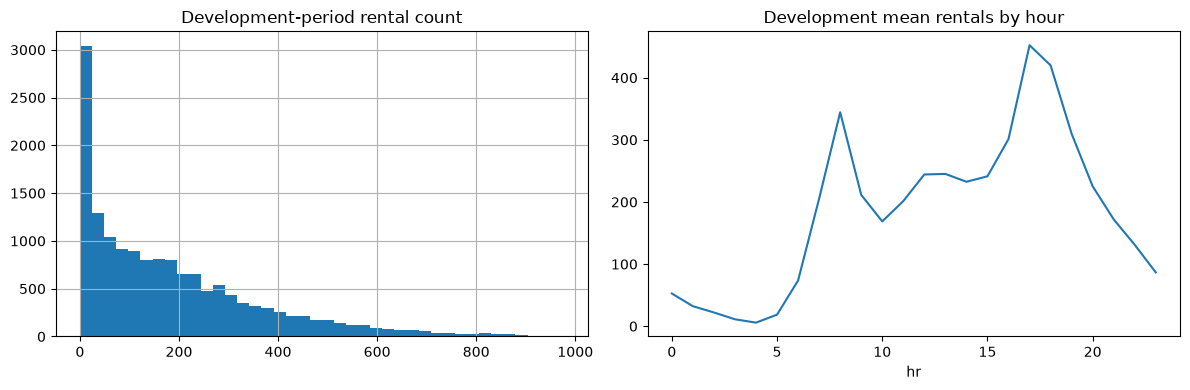

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
development["cnt"].hist(bins=40, ax=axes[0]); axes[0].set_title("Development-period rental count")
development.groupby("hr")["cnt"].mean().plot(ax=axes[1]); axes[1].set_title("Development mean rentals by hour")
plt.tight_layout()

**Data-quality record:** The UCI hourly file omits 165 hour rows, but all 731 daily totals exactly match summed observed hourly counts. The analysis adds those slots as zero-demand hours; the completed series contains 17,544 hourly slots and no missing timestamps. The Q4 test is all 2,208 hours.


## 3. Data Preparation

**Purpose and tasks.** Select rows/attributes; clean and construct variables; integrate sources if needed; format the model table; prevent target leakage and document the split.

**Phase intent.** Document feature inclusion/exclusion, transformations, split logic, and leakage controls in code.

**Project-specific decision.** UCI Bike Sharing (hourly), also used in Kaggle's Bike Sharing Demand competition; 17,379 hourly observations with weather and calendar fields. The target is cnt. casual and registered are excluded because they sum to cnt and would leak the answer.

**Expected evidence.** The model uses all 17,544 validated hourly slots, including zero-demand slots, and only month/weekday/hour/trend features. The Q4 test is a complete 2,208-hour grid.

**Independent critique and revision record.** GPT-5.6 review pass 1 identified target-hour weather leakage, a mismatch between aggregate rentals and station redistribution, insufficient temporal validation, and missing baseline/acceptance evidence. The revised analysis uses calendar-only features, rolling-origin validation, an untouched Q4 holdout, a weekday/hour baseline, and a predeclared gate. GPT-5.6 review pass 2 found hour.csv omits 165 time slots (40 in Q4), but those slots reconcile to zero against day.csv totals and caught imprecise season wording; the report now describes the complete zero-reconciled 2,208-hour holdout and source season codes accurately. GPT-5.6 pass 3 caught the signed-error direction; negative actual-minus-prediction bias is correctly described as overprediction in the report and article. Setup dependencies are pinned, and source archive/member hashes are asserted before analysis.

In [5]:
assert hour_observed.timestamp.is_monotonic_increasing and hour_observed.instant.is_unique and hour_observed.timestamp.is_unique
assert (hour_observed.cnt == hour_observed.casual + hour_observed.registered).all()
assert hour_observed.temp.between(0,1).all() and hour_observed.hum.between(0,1).all()
assert df.timestamp.is_monotonic_increasing and df.timestamp.is_unique
assert df.cnt.ge(0).all() and df.cnt.notna().all()
assert df.is_zero_filled.sum()==len(missing_source_hours) and len(q4_source_missing)==40
assert len(development)>0 and len(final_holdout)==2208
# Day-ahead features are known at the forecast origin. Target-hour weather is excluded.
def calendar_features(timestamps):
    ts = pd.Series(pd.to_datetime(timestamps)).reset_index(drop=True)
    return pd.DataFrame({"month":ts.dt.month.astype(str),"weekday":ts.dt.dayofweek.astype(str),"hour":ts.dt.hour.astype(str),"days_since_start":(ts-pd.Timestamp("2011-01-01")).dt.total_seconds()/86400})
categorical = ["month","weekday","hour"]
dev_timestamps, y_dev = development.timestamp.reset_index(drop=True), development.cnt.reset_index(drop=True)
holdout_timestamps, y_holdout = final_holdout.timestamp.reset_index(drop=True), final_holdout.cnt.reset_index(drop=True)
X_dev, X_holdout = calendar_features(dev_timestamps), calendar_features(holdout_timestamps)
print("development period",dev_timestamps.min(),"through",dev_timestamps.max(),"final holdout",holdout_timestamps.min(),"through",holdout_timestamps.max())
print("forecast-origin feature contract",list(X_dev.columns),"target-hour weather excluded","validated zero hours included")


development period 2011-01-01 00:00:00 through 2012-09-30 23:00:00 final holdout 2012-10-01 00:00:00 through 2012-12-31 23:00:00
forecast-origin feature contract ['month', 'weekday', 'hour', 'days_since_start'] target-hour weather excluded validated zero hours included


/var/folders/nm/f0h8252n2mx34fvh7bw4kw0c0000gp/T/ipykernel_72779/2479530765.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  return pd.DataFrame({"month":ts.dt.month.astype(str),"weekday":ts.dt.dayofweek.astype(str),"hour":ts.dt.hour.astype(str),"days_since_start":(ts-pd.Timestamp("2011-01-01")).dt.total_seconds()/86400})
/var/folders/nm/f0h8252n2mx34fvh7bw4kw0c0000gp/T/ipykernel_72779/2479530765.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  return pd.DataFrame({"month":ts.dt.month.astype(str),"weekday":ts.dt.dayofweek.astype(str),"hour":ts.dt.hour.astype(str),"days_since_start":(ts-pd.Timestamp("2011-01-01")).dt.total_seconds()/86400})


## 4. Modeling

**Purpose and tasks.** Select modeling technique; create test design; build baseline and candidate; assess model settings and reproducibility.

**Phase intent.** Fit a transparent baseline and a documented candidate using reproducible settings.

**Project-specific decision.** UCI Bike Sharing (hourly), also used in Kaggle's Bike Sharing Demand competition; 17,379 hourly observations with weather and calendar fields. The target is cnt. casual and registered are excluded because they sum to cnt and would leak the answer.

**Expected evidence.** Rolling-origin validation selects calendar HGB (MAE 60.88 vs baseline 95.42), but the Q4 holdout reverses the result: HGB MAE 97.00 vs baseline 81.10 on the completed zero-inclusive hourly grid. Final holdout results govern the no-go decision.

**Independent critique and revision record.** GPT-5.6 review pass 1 identified target-hour weather leakage, a mismatch between aggregate rentals and station redistribution, insufficient temporal validation, and missing baseline/acceptance evidence. The revised analysis uses calendar-only features, rolling-origin validation, an untouched Q4 holdout, a weekday/hour baseline, and a predeclared gate. GPT-5.6 review pass 2 found hour.csv omits 165 time slots (40 in Q4), but those slots reconcile to zero against day.csv totals and caught imprecise season wording; the report now describes the complete zero-reconciled 2,208-hour holdout and source season codes accurately. GPT-5.6 pass 3 caught the signed-error direction; negative actual-minus-prediction bias is correctly described as overprediction in the report and article. Setup dependencies are pinned, and source archive/member hashes are asserted before analysis.

In [6]:
def build_calendar_model():
    prep = ColumnTransformer([("categorical",OneHotEncoder(handle_unknown="ignore",sparse_output=False),categorical),("trend","passthrough",["days_since_start"])])
    reg = HistGradientBoostingRegressor(loss="absolute_error",max_iter=150,learning_rate=0.08,early_stopping=False,random_state=42)
    return Pipeline([("prep",prep),("regressor",reg)])
def score_nonnegative(fitted_model,timestamps):
    return np.maximum(0,fitted_model.predict(calendar_features(timestamps)))
def weekday_hour_baseline(train_frame,query_timestamps):
    train_features = calendar_features(train_frame.timestamp)
    medians = pd.concat([train_features[["weekday","hour"]],train_frame.cnt.reset_index(drop=True).rename("target")],axis=1).groupby(["weekday","hour"])["target"].median()
    query = calendar_features(query_timestamps)
    return np.array([medians.get((w,h),train_frame.cnt.median()) for w,h in zip(query.weekday,query.hour)])
def reg_metrics(actual,pred):
    pred = np.maximum(0,np.asarray(pred)); actual = np.asarray(actual)
    return {"MAE":mean_absolute_error(actual,pred),"RMSE":mean_squared_error(actual,pred)**0.5,"RMSLE":mean_squared_log_error(actual,pred)**0.5}
# Rolling-origin development folds: train only on dates before each month; assess Jan–Sep 2012.
validation_rows = []
for month in range(1,10):
    start = pd.Timestamp(year=2012,month=month,day=1); end = start + pd.offsets.MonthBegin(1)
    fold_train = development[development.timestamp < start]; fold_valid = development[(development.timestamp >= start)&(development.timestamp < end)]
    fold_model = build_calendar_model().fit(calendar_features(fold_train.timestamp),fold_train.cnt)
    fold_pred = score_nonnegative(fold_model,fold_valid.timestamp)
    base_pred = weekday_hour_baseline(fold_train,fold_valid.timestamp)
    validation_rows.append(pd.DataFrame({"timestamp":fold_valid.timestamp,"actual":fold_valid.cnt,"candidate":fold_pred,"baseline":base_pred,"month":month}))
validation_predictions = pd.concat(validation_rows,ignore_index=True)
validation_summary = pd.DataFrame({"median_weekday_hour":reg_metrics(validation_predictions.actual,validation_predictions.baseline),"calendar_HGB":reg_metrics(validation_predictions.actual,validation_predictions.candidate)}).T
display(validation_summary)
validation_winner = "calendar_HGB" if validation_summary.loc["calendar_HGB","MAE"] < validation_summary.loc["median_weekday_hour","MAE"] else "median_weekday_hour"
print("Selected from Jan–Sep rolling validation:",validation_winner)
# Freeze selection; fit through Sep 2012, then evaluate the untouched Oct–Dec block once.
final_model = build_calendar_model().fit(X_dev,y_dev)
candidate_pred = score_nonnegative(final_model,holdout_timestamps)
baseline_pred = weekday_hour_baseline(development,holdout_timestamps)
final_metrics = pd.DataFrame({"median_weekday_hour":reg_metrics(y_holdout,baseline_pred),"calendar_HGB":reg_metrics(y_holdout,candidate_pred)}).T
display(final_metrics)

/var/folders/nm/f0h8252n2mx34fvh7bw4kw0c0000gp/T/ipykernel_72779/2479530765.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  return pd.DataFrame({"month":ts.dt.month.astype(str),"weekday":ts.dt.dayofweek.astype(str),"hour":ts.dt.hour.astype(str),"days_since_start":(ts-pd.Timestamp("2011-01-01")).dt.total_seconds()/86400})


/var/folders/nm/f0h8252n2mx34fvh7bw4kw0c0000gp/T/ipykernel_72779/2479530765.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  return pd.DataFrame({"month":ts.dt.month.astype(str),"weekday":ts.dt.dayofweek.astype(str),"hour":ts.dt.hour.astype(str),"days_since_start":(ts-pd.Timestamp("2011-01-01")).dt.total_seconds()/86400})
/var/folders/nm/f0h8252n2mx34fvh7bw4kw0c0000gp/T/ipykernel_72779/2479530765.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  return pd.DataFrame({"month":ts.dt.month.astype(str),"weekday":ts.dt.dayofweek.astype(str),"hour":ts.dt.hour.astype(str),"days_since_start":(ts-pd.Timestamp("2011-01-01")).dt.total_seconds()/86400})
/var/folders/nm/f0h8252n2mx34fvh7bw4kw0c0000gp/T/ipykernel_72779/2479530765.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Se

/var/folders/nm/f0h8252n2mx34fvh7bw4kw0c0000gp/T/ipykernel_72779/2479530765.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  return pd.DataFrame({"month":ts.dt.month.astype(str),"weekday":ts.dt.dayofweek.astype(str),"hour":ts.dt.hour.astype(str),"days_since_start":(ts-pd.Timestamp("2011-01-01")).dt.total_seconds()/86400})
/var/folders/nm/f0h8252n2mx34fvh7bw4kw0c0000gp/T/ipykernel_72779/2479530765.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  return pd.DataFrame({"month":ts.dt.month.astype(str),"weekday":ts.dt.dayofweek.astype(str),"hour":ts.dt.hour.astype(str),"days_since_start":(ts-pd.Timestamp("2011-01-01")).dt.total_seconds()/86400})
/var/folders/nm/f0h8252n2mx34fvh7bw4kw0c0000gp/T/ipykernel_72779/2479530765.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Se

/var/folders/nm/f0h8252n2mx34fvh7bw4kw0c0000gp/T/ipykernel_72779/2479530765.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  return pd.DataFrame({"month":ts.dt.month.astype(str),"weekday":ts.dt.dayofweek.astype(str),"hour":ts.dt.hour.astype(str),"days_since_start":(ts-pd.Timestamp("2011-01-01")).dt.total_seconds()/86400})
/var/folders/nm/f0h8252n2mx34fvh7bw4kw0c0000gp/T/ipykernel_72779/2479530765.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  return pd.DataFrame({"month":ts.dt.month.astype(str),"weekday":ts.dt.dayofweek.astype(str),"hour":ts.dt.hour.astype(str),"days_since_start":(ts-pd.Timestamp("2011-01-01")).dt.total_seconds()/86400})
/var/folders/nm/f0h8252n2mx34fvh7bw4kw0c0000gp/T/ipykernel_72779/2479530765.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Se

/var/folders/nm/f0h8252n2mx34fvh7bw4kw0c0000gp/T/ipykernel_72779/2479530765.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  return pd.DataFrame({"month":ts.dt.month.astype(str),"weekday":ts.dt.dayofweek.astype(str),"hour":ts.dt.hour.astype(str),"days_since_start":(ts-pd.Timestamp("2011-01-01")).dt.total_seconds()/86400})
/var/folders/nm/f0h8252n2mx34fvh7bw4kw0c0000gp/T/ipykernel_72779/2479530765.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  return pd.DataFrame({"month":ts.dt.month.astype(str),"weekday":ts.dt.dayofweek.astype(str),"hour":ts.dt.hour.astype(str),"days_since_start":(ts-pd.Timestamp("2011-01-01")).dt.total_seconds()/86400})
/var/folders/nm/f0h8252n2mx34fvh7bw4kw0c0000gp/T/ipykernel_72779/2479530765.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Se

/var/folders/nm/f0h8252n2mx34fvh7bw4kw0c0000gp/T/ipykernel_72779/2479530765.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  return pd.DataFrame({"month":ts.dt.month.astype(str),"weekday":ts.dt.dayofweek.astype(str),"hour":ts.dt.hour.astype(str),"days_since_start":(ts-pd.Timestamp("2011-01-01")).dt.total_seconds()/86400})
/var/folders/nm/f0h8252n2mx34fvh7bw4kw0c0000gp/T/ipykernel_72779/2479530765.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  return pd.DataFrame({"month":ts.dt.month.astype(str),"weekday":ts.dt.dayofweek.astype(str),"hour":ts.dt.hour.astype(str),"days_since_start":(ts-pd.Timestamp("2011-01-01")).dt.total_seconds()/86400})
/var/folders/nm/f0h8252n2mx34fvh7bw4kw0c0000gp/T/ipykernel_72779/2479530765.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Se

... (4 outputs left out)

,MAE,RMSE,RMSLE
median_weekday_hour,95.420620,136.943296,0.562480
calendar_HGB,60.877281,95.251591,0.622712


Selected from Jan–Sep rolling validation: calendar_HGB


/var/folders/nm/f0h8252n2mx34fvh7bw4kw0c0000gp/T/ipykernel_72779/2479530765.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  return pd.DataFrame({"month":ts.dt.month.astype(str),"weekday":ts.dt.dayofweek.astype(str),"hour":ts.dt.hour.astype(str),"days_since_start":(ts-pd.Timestamp("2011-01-01")).dt.total_seconds()/86400})
/var/folders/nm/f0h8252n2mx34fvh7bw4kw0c0000gp/T/ipykernel_72779/2479530765.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  return pd.DataFrame({"month":ts.dt.month.astype(str),"weekday":ts.dt.dayofweek.astype(str),"hour":ts.dt.hour.astype(str),"days_since_start":(ts-pd.Timestamp("2011-01-01")).dt.total_seconds()/86400})
/var/folders/nm/f0h8252n2mx34fvh7bw4kw0c0000gp/T/ipykernel_72779/2479530765.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Se

,MAE,RMSE,RMSLE
median_weekday_hour,81.097826,122.347840,0.843090
calendar_HGB,97.004791,148.585432,1.043853


## 5. Evaluation

**Purpose and tasks.** Evaluate the analytical screening criteria, identify unresolved business success, review process risks, and decide whether operational use is supported.

**Phase intent.** Use metrics aligned to the task, inspect slices and failure cases, and distinguish measured evidence from proposed acceptance criteria.

**Project-specific decision.** The analytical screening gate is a back-tested MAE at least 10% lower than a training-period median-by-weekday-and-hour baseline, and candidate MAE no more than 10% worse than that baseline within any held-out season. These are proposed acceptance thresholds. Stakeholders: dispatch planners, operations lead, data owner. Constraints: historical association is not causal; weather forecast availability and drift matter.

**Expected evidence.** The candidate is 19.6% worse overall, fails the represented source-season-code guardrail, has signed error −72.24 (actual minus prediction; overprediction), and day-block candidate-minus-baseline MAE interval [3.52, 27.79]. Both gates fail.

**Independent critique and revision record.** GPT-5.6 review pass 1 identified target-hour weather leakage, a mismatch between aggregate rentals and station redistribution, insufficient temporal validation, and missing baseline/acceptance evidence. The revised analysis uses calendar-only features, rolling-origin validation, an untouched Q4 holdout, a weekday/hour baseline, and a predeclared gate. GPT-5.6 review pass 2 found hour.csv omits 165 time slots (40 in Q4), but those slots reconcile to zero against day.csv totals and caught imprecise season wording; the report now describes the complete zero-reconciled 2,208-hour holdout and source season codes accurately. GPT-5.6 pass 3 caught the signed-error direction; negative actual-minus-prediction bias is correctly described as overprediction in the report and article. Setup dependencies are pinned, and source archive/member hashes are asserted before analysis.

In [7]:
final_results = final_holdout[["timestamp","season","mnth","hr","weekday","workingday","cnt"]].copy().rename(columns={"cnt":"actual"})
final_results["candidate"] = candidate_pred; final_results["baseline"] = baseline_pred
final_results["absolute_error"] = np.abs(final_results.actual-final_results.candidate)
final_results["signed_error"] = final_results.actual-final_results.candidate
season_scores = final_results.groupby("season").apply(lambda g: pd.Series({"n":len(g),"candidate_MAE":mean_absolute_error(g.actual,g.candidate),"baseline_MAE":mean_absolute_error(g.actual,g.baseline),"relative_MAE_change":mean_absolute_error(g.actual,g.candidate)/mean_absolute_error(g.actual,g.baseline)-1}))
display(season_scores)
display(final_results.groupby("mnth").apply(lambda g: pd.Series({"n":len(g),"candidate_MAE":mean_absolute_error(g.actual,g.candidate),"baseline_MAE":mean_absolute_error(g.actual,g.baseline)})))
final_results["actual_demand_quartile"] = pd.qcut(final_results.actual,4,duplicates="drop")
display(final_results.groupby("actual_demand_quartile",observed=True).agg(n=("absolute_error","size"),candidate_MAE=("absolute_error","mean"),mean_signed_error=("signed_error","mean")))
overall_pass = final_metrics.loc["calendar_HGB","MAE"] <= .9*final_metrics.loc["median_weekday_hour","MAE"]
season_pass = season_scores.relative_MAE_change.max() <= .10
print("Q4 analytical gate overall / represented seasons:",overall_pass,season_pass,"rolling-validation choice:",validation_winner)
print("holdout",holdout_timestamps.min(),"through",holdout_timestamps.max(),"candidate signed error mean",final_results.signed_error.mean(),"P90 absolute error",final_results.absolute_error.quantile(.90))
# Resample whole days to preserve within-day dependence. Difference is candidate MAE minus baseline MAE.
daily = final_results.assign(date=final_results.timestamp.dt.date).groupby("date").apply(lambda g: pd.Series({"n":len(g),"candidate_abs":g.absolute_error.sum(),"baseline_abs":np.abs(g.actual-g.baseline).sum()}))
rng=np.random.default_rng(42); gaps=[]
for _ in range(1000):
    sample=daily.iloc[rng.integers(0,len(daily),size=len(daily))]
    gaps.append((sample.candidate_abs.sum()-sample.baseline_abs.sum())/sample.n.sum())
print("Day-block bootstrap 95% interval for candidate-minus-baseline MAE:",np.quantile(gaps,[.025,.975]))


,n,candidate_MAE,baseline_MAE,relative_MAE_change
season,,,,
1,264.0,201.870488,107.878788,0.871271
4,1944.0,82.763771,77.460905,0.068459


,n,candidate_MAE,baseline_MAE
mnth,,,
10,744.0,74.696027,113.438172
11,720.0,96.610301,60.243056
12,744.0,119.695321,68.939516


,n,candidate_MAE,mean_signed_error
actual_demand_quartile,,,
"(-0.001, 40.0]",556,60.692945,-60.300701
"(40.0, 167.5]",548,130.898329,-127.522457
"(167.5, 323.0]",553,97.143723,-92.198977
"(323.0, 963.0]",551,99.797711,-9.276960


Q4 analytical gate overall / represented seasons: False False rolling-validation choice: calendar_HGB
holdout 2012-10-01 00:00:00 through 2012-12-31 23:00:00 candidate signed error mean -72.24055060816589 P90 absolute error 241.61026360192858
Day-block bootstrap 95% interval for candidate-minus-baseline MAE: [ 3.52219133 27.78957795]


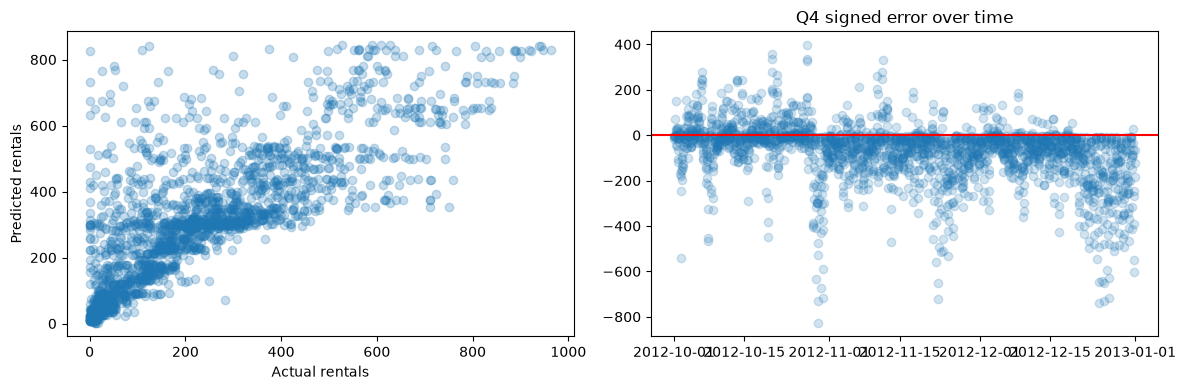

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(final_results.actual,final_results.candidate,alpha=.25); axes[0].set_xlabel("Actual rentals"); axes[0].set_ylabel("Predicted rentals")
axes[1].scatter(final_results.timestamp,final_results.signed_error,alpha=.2); axes[1].axhline(0,color="red"); axes[1].set_title("Q4 signed error over time")
plt.tight_layout()


**Evaluation record:** The saved outputs below contain the measured metrics and gate decision. The candidate fails both proposed gates; interpret this as a no-go for operational use.

## 6. Deployment

**Purpose and tasks.** Plan deployment, monitoring, maintenance, and final reporting; identify owner, rollback, and next iteration.

**Phase intent.** Package a scoring artifact and operational checklist; deployment here means a reproducible handoff, not a live production service.

**Project-specific decision.** UCI Bike Sharing (hourly), also used in Kaggle's Bike Sharing Demand competition; 17,379 hourly observations with weather and calendar fields. The target is cnt. casual and registered are excluded because they sum to cnt and would leak the answer.

**Expected evidence.** The saved artifact is marked `research_backtest_not_operationally_approved`; it is not an operational candidate. Redevelopment and a newly passing evaluation are prerequisites before any deployment consideration.

**Independent critique and revision record.** GPT-5.6 review pass 1 identified target-hour weather leakage, a mismatch between aggregate rentals and station redistribution, insufficient temporal validation, and missing baseline/acceptance evidence. The revised analysis uses calendar-only features, rolling-origin validation, an untouched Q4 holdout, a weekday/hour baseline, and a predeclared gate. GPT-5.6 review pass 2 found hour.csv omits 165 time slots (40 in Q4), but those slots reconcile to zero against day.csv totals and caught imprecise season wording; the report now describes the complete zero-reconciled 2,208-hour holdout and source season codes accurately. GPT-5.6 pass 3 caught the signed-error direction; negative actual-minus-prediction bias is correctly described as overprediction in the report and article. Setup dependencies are pinned, and source archive/member hashes are asserted before analysis.

## Deployment decision

The present artifact is not an operational candidate: the untouched Q4 evaluation fails both data-mining gates and business utility has not been established. The saved artifact and scores exist only for reproducibility. Redevelopment, a decision-specific cost/utility study, and a newly passing temporal evaluation are prerequisites before any operational consideration.


In [9]:
import joblib, sys
artifact = {"pipeline":final_model,"feature_contract":"timestamp -> calendar_features(month, weekday, hour, days_since_start)","target":"cnt","training_cutoff":str(dev_timestamps.max()),"methodology":"CRISP-DM","artifact_version":"1.0","schema_version":1,"status":"research_backtest_not_operationally_approved","archive_sha256":archive_sha256,"hour_csv_sha256":csv_sha256,"day_csv_sha256":day_sha256,"zero_hour_policy":"daily totals reconcile exactly; omitted hourly slots included as zero","training_rows":len(y_dev),"retrieved_utc":retrieved_utc,"versions":{"python":sys.version,"pandas":pd.__version__,"numpy":np.__version__,"scikit_learn":sklearn.__version__}}
joblib.dump(artifact,"bike_demand_calendar_model.joblib")
scored=pd.DataFrame({"timestamp":holdout_timestamps.iloc[:100]})
scored["predicted_cnt"]=score_nonnegative(artifact["pipeline"],scored.timestamp)
scored.to_csv("bike_demand_q4_sample_scoring.csv",index=False)
assert np.allclose(scored.predicted_cnt.to_numpy(),candidate_pred[:100])
print("Saved local research artifact and Q4 sample scores; scorer matches evaluation. No operational approval is established.")


Saved local research artifact and Q4 sample scores; scorer matches evaluation. No operational approval is established.


/var/folders/nm/f0h8252n2mx34fvh7bw4kw0c0000gp/T/ipykernel_72779/2479530765.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  return pd.DataFrame({"month":ts.dt.month.astype(str),"weekday":ts.dt.dayofweek.astype(str),"hour":ts.dt.hour.astype(str),"days_since_start":(ts-pd.Timestamp("2011-01-01")).dt.total_seconds()/86400})


## Limitations, ethics, and next iteration

The data cover one system in 2011–2012. The hourly source omits 165 rows; these are assigned zero demand only because all 731 daily totals exactly reconcile to the sums of observed hourly counts. The Q4 test is complete after this reconciliation, but only one quarter is held out and season codes 2 and 3 are absent. The system-wide target cannot locate station shortages. The candidate fails both analytical gates, business utility remains unresolved, and the time trend may not transfer to current demand. A next study needs station-level trip/inventory data, multiple forecast-origin tests across all seasons and years, and planner-defined error costs. Do not use the present model operationally.


## References

- CRISP-DM: Chapman et al., *CRISP-DM 1.0: Step-by-step data mining guide* (2000), [IBM-hosted PDF](https://public.dhe.ibm.com/software/analytics/spss/documentation/modeler/14.2/es/CRISP-DM.pdf).
- SEMMA: SAS, [Data Mining and SEMMA](https://support.sas.com/documentation/cdl/en/emcs/66392/HTML/default/n0pejm83csbja4n1xueveo2uoujy.htm).
- KDD: Fayyad, Piatetsky-Shapiro, and Smyth (1996), [The KDD Process for Extracting Useful Knowledge](https://doi.org/10.1145/240455.240464).
- Dataset provenance is linked in the charter; consult the original dataset page for the definitive citation and license.